# Regresión Lineal con Sklearn: Guía Completa con Ejemplos


Carlos Francisco Montoya Urzua



https://www.datacamp.com/tutorial/sklearn-linear-regression

La regresión lineal es una técnica fundamental en estadística y aprendizaje automático que ayuda a modelar la relación entre variables. En términos simples, nos permite predecir un resultado basándose en uno o más factores de influencia. Se aplica ampliamente en precios de bienes raíces, pronóstico de ventas, evaluación de riesgos y muchos otros campos.


## Regresión Lineal y  Aprendizaje Automático

Más allá de su utilidad inmediata para determinar precios de viviendas, la regresión lineal juega un papel importante en el aprendizaje automático.

- Es un modelo fundamental para comprender técnicas más avanzadas como la regresión logística, las redes neuronales y las máquinas de soporte vectorial.
- Es rápida de entrenar, lo que la hace ideal para la creación rápida de prototipos.
- También sirve como línea base de comparación. Si los modelos más avanzados no la superan significativamente, su complejidad adicional puede no estar justificada.
- A diferencia de algunas técnicas (como el aprendizaje profundo), es fácilmente interpretable.
- Puede ayudar en la selección de características, identificando los predictores más útiles.

A pesar de su simplicidad, la regresión lineal sigue siendo una herramienta indispensable en el aprendizaje automático debido a su eficiencia, interpretabilidad y versatilidad.

## Regresión Lineal y la Biblioteca scikit-learn

La libreria scikit-learn facilita la implementación de la regresión lineal. Esta librería tiene muchas ventajas.

- Tiene una interfaz consistente. El código necesario para implementar distintos algoritmos de ML es similar.
- El código es sencillo, con detalles matemáticos y de implementación complejos abstraídos. Por ejemplo, para ajustar un modelo a datos de entrenamiento, simplemente usa `model.fit(X_train, y_train)`.
- Proporciona fácil acceso a los coeficientes del modelo.
- Provee métricas integradas para evaluar el rendimiento del modelo.
- Es fácil integrar la regresión lineal (o cualquier otro algoritmo de ML) con pasos de preprocesamiento, como escalado y selección de características, usando `Pipeline`.

## Entendiendo la Regresión Lineal

En la regresión lineal simple, los datos se modelan usando una "línea de mejor ajuste". La fórmula para esta línea es:

$$y = mx + b$$

donde *m* es la pendiente de la línea y *b* es el intercepto.

La "regresión lineal múltiple" generaliza el caso de un predictor a varios predictores (número de habitaciones, proximidad al océano, ingreso medio del vecindario). La fórmula se generaliza a:

$$y = b_0 + b_1 x_1 + b_2 x_2 + \ldots + b_n x_n$$

donde cada $x_i$ es una variable independiente y el correspondiente $b_i$ es su coeficiente. En tres dimensiones, la línea se generaliza a un plano. En dimensiones superiores, el plano se convierte en un "hiperplano".

¿Cómo interpretamos los coeficientes y el intercepto? El intercepto es el valor predicho de *y* cuando todas las variables independientes son 0, o dicho de otra forma, es el valor base de la variable dependiente cuando no hay contribución de los predictores. Cada coeficiente $b_i$ representa el cambio en la variable dependiente *y* por un cambio de una unidad en $x_i$, manteniendo constantes todas las demás variables independientes.

## Configuración del Entorno

Instalar scikit-learn es sencillo. Simplemente usa el comando `pip install scikit-learn`. Si deseas instalar una versión específica, por ejemplo 1.2.2, modifica el comando para incluir la versión: `pip install scikit-learn==1.2.2`. Si usas Anaconda, scikit-learn ya debería estar instalado.

Varias bibliotecas son necesarias o recomendadas al usar scikit-learn. La biblioteca `numpy` es necesaria para almacenar características y etiquetas. La biblioteca `pandas` es recomendada para cargar, preprocesar y explorar conjuntos de datos.

Para graficar los resultados, lo más probable es que uses `matplotlib` o `seaborn` o ambas. Cualquiera de estas bibliotecas puede instalarse usando pip install. Incluso puedes instalar múltiples bibliotecas con un solo comando:

In [ ]:
# Instalar las bibliotecas necesarias (ejecutar si es necesario)
# !pip install scikit-learn numpy pandas matplotlib seaborn

## Implementando la Regresión Lineal en sklearn

Antes de cargar el conjunto de datos, importemos las bibliotecas habituales.

In [ ]:
# Importar librerias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Cargando el Conjunto de Datos

Usemos el conocido conjunto de datos de viviendas de California.

In [ ]:
# Leer el conjunto de datos de viviendas de California.
from sklearn.datasets import fetch_california_housing


housing = fetch_california_housing()
housing

{'data': array([[   8.3252    ,   41.        ,    6.98412698, ...,    2.55555556,
           37.88      , -122.23      ],
        [   8.3014    ,   21.        ,    6.23813708, ...,    2.10984183,
           37.86      , -122.22      ],
        [   7.2574    ,   52.        ,    8.28813559, ...,    2.80225989,
           37.85      , -122.24      ],
        ...,
        [   1.7       ,   17.        ,    5.20554273, ...,    2.3256351 ,
           39.43      , -121.22      ],
        [   1.8672    ,   18.        ,    5.32951289, ...,    2.12320917,
           39.43      , -121.32      ],
        [   2.3886    ,   16.        ,    5.25471698, ...,    2.61698113,
           39.37      , -121.24      ]]),
 'target': array([4.526, 3.585, 3.521, ..., 0.923, 0.847, 0.894]),
 'frame': None,
 'target_names': ['MedHouseVal'],
 'feature_names': ['MedInc',
  'HouseAge',
  'AveRooms',
  'AveBedrms',
  'Population',
  'AveOccup',
  'Latitude',
  'Longitude'],
 'DESCR': '.. _california_housing_dataset:\n

### Preparación de los Datos

Dividamos los datos en conjuntos de entrenamiento y prueba. Importamos el método `train_test_split()` de `sklearn.model_selection`, luego lo invocamos, especificando un porcentaje del conjunto de prueba y un `random_state`. También usaremos regresión lineal simple, usando la característica correspondiente al número promedio de habitaciones.

In [ ]:
# Importar train_test_split.
from sklearn.model_selection import train_test_split


# Crear características X y objetivo y.
X = pd.DataFrame(housing.data, columns=housing.feature_names)[["AveRooms"]]
y = housing.target  # Valor mediano de la vivienda en $100,000s


# Dividir el conjunto de datos en entrenamiento (80%) y prueba (20%).
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
X

,AveRooms
0,6.984127
1,6.238137
2,8.288136
3,5.817352
4,6.281853
...,...
20635,5.045455
20636,6.114035
20637,5.205543
20638,5.329513


In [ ]:
y

array([4.526, 3.585, 3.521, ..., 0.923, 0.847, 0.894])

In [ ]:
X_train

,AveRooms
14196,5.017657
8267,4.473545
17445,5.645833
14265,4.002817
2271,6.268421
...,...
11284,6.129032
11964,6.868597
5390,3.986717
860,6.395349


In [ ]:
X_test

,AveRooms
20046,4.192201
3024,5.039384
15663,3.977155
20484,6.163636
9814,5.492991
...,...
15362,7.002212
16623,6.131915
18086,7.237676
2144,5.289030


In [ ]:
y_train

array([1.03 , 3.821, 1.726, ..., 2.221, 2.835, 3.25 ])

In [ ]:
y_test

array([0.477  , 0.458  , 5.00001, ..., 5.00001, 0.723  , 1.515  ])

Ahora que hemos dividido los datos en conjuntos de prueba y entrenamiento, estandaricemos las características. Este proceso garantiza que todas las variables estén en la misma escala, lo que puede mejorar el rendimiento del modelo y la estabilidad numérica.

In [ ]:
# Importar StandardScaler.
from sklearn.preprocessing import StandardScaler

# Instanciar StandardScaler.
scaler = StandardScaler()

# Ajustar y transformar los datos de entrenamiento.
X_train_scaled = scaler.fit_transform(X_train)

# También transformar los datos de prueba.
X_test_scaled = scaler.transform(X_test)

In [ ]:
scaler

StandardScaler()

In [ ]:
X_train_scaled

array([[-0.17491646],
       [-0.40283542],
       [ 0.08821601],
       ...,
       [-0.60675918],
       [ 0.40217517],
       [-0.85144571]])

In [ ]:
X_test_scaled

array([[-0.52068576],
       [-0.16581537],
       [-0.61076476],
       ...,
       [ 0.75501156],
       [-0.06124296],
       [-0.6058703 ]])

En este código, `StandardScaler` es una herramienta de preprocesamiento de datos que elimina la media y escala las características a varianza unitaria. Esto ayuda a evitar que ciertas características dominen el modelo debido a diferencias en escala.

El escalador se ajusta a los datos de entrenamiento usando el método `fit_transform()`. Los datos de prueba se transforman por separado usando el método `transform()` para garantizar que se escalen con los mismos factores que los datos de entrenamiento, previniendo la fuga de datos.

### Entrenando el Modelo de Regresión Lineal

Para crear un modelo de regresión lineal, importa `LinearRegression()` de `sklearn.linear_model`. Instáncialo y asígnalo a una variable.

In [ ]:
# Importar LinearRegression.
from sklearn.linear_model import LinearRegression


# Instanciar el modelo de regresión lineal.
model = LinearRegression()
model

LinearRegression()

Ajustar el modelo con los datos de entrenamiento es sencillo.

In [ ]:
# Ajustar el modelo a los datos de entrenamiento.
model.fit(X_train_scaled, y_train)

LinearRegression()

### Haciendo Predicciones

Ahora que hemos entrenado nuestro modelo, hacemos predicciones sobre el conjunto de prueba.

In [ ]:
# Hacer predicciones sobre los datos de prueba.
y_pred = model.predict(X_test_scaled)
y_pred

array([1.97653709, 2.04156313, 1.96003112, ..., 2.21029436, 2.06072485,
       1.96092798])

### Evaluación del Rendimiento del Modelo

Ahora que hemos hecho predicciones sobre el conjunto de prueba, necesitamos saber qué tan bien se corresponden con la realidad. Existen varias métricas disponibles para evaluar el rendimiento de un algoritmo de regresión. Algunas de las más comunes son el coeficiente de determinación (R²), el error cuadrático medio (MSE) y la raíz del error cuadrático medio (RMSE).

El coeficiente de determinación, denotado R², mide qué tan bien un modelo de regresión explica la variabilidad de la variable objetivo. En otras palabras, cuantifica cuánta variabilidad en la variable objetivo es explicada por los predictores, lo que se conoce como la bondad de ajuste.

La fórmula es:

$$R^2 = 1 - \frac{\sum(y_{\text{real}} - y_{\text{predicho}})^2}{\sum(y_{\text{real}} - \bar{y})^2}$$

donde $y_{\text{real}}$ son los valores reales de la variable objetivo, $y_{\text{predicho}}$ son los valores predichos por el modelo y $\bar{y}$ es la media de los valores reales.

¿Cómo interpretamos R²?

- **R² = 1**: el modelo explica perfectamente toda la varianza en la variable objetivo.
- **R² = 0**: el modelo no explica nada de la varianza; las predicciones no son mejores que usar simplemente la media.
- **R² < 0**: el modelo funciona peor que simplemente usar la media, lo que indica un ajuste deficiente.

Algunas consideraciones clave a tener en cuenta:

- Un R² más alto no siempre es mejor. Un R² alto puede indicar sobreajuste, especialmente con modelos complejos.
- Agregar más características puede aumentar artificialmente el R², por lo que un valor más alto no necesariamente es mejor.
- Para la regresión múltiple, usa el R² ajustado, que tiene en cuenta el número de predictores y evita mejoras engañosas por variables innecesarias.

In [ ]:
# Importar métricas.
from sklearn.metrics import mean_squared_error, r2_score


# Calcular e imprimir la puntuación R².
r2 = r2_score(y_test, y_pred)
print(f"R-cuadrado: {r2:.4f}")

R-cuadrado: 0.0138


Otras métricas de uso común son el error cuadrático medio (MSE) y la raíz del error cuadrático medio (RMSE). Estas métricas miden qué tan lejos se desvían las predicciones del modelo de los valores reales.

El MSE calcula la diferencia cuadrática promedio entre los valores reales y los predichos:

$$MSE = \frac{1}{n} \sum_{i=1}^{n}(y_i - \hat{y}_i)^2$$

para el número total de observaciones *n*. Dado que los errores se elevan al cuadrado antes de promediar, los errores grandes se penalizan más que los pequeños, lo que hace que el MSE sea sensible a los valores atípicos. Un MSE más bajo indica un mejor ajuste del modelo.

Para abordar esta situación, se usa el RMSE, que es simplemente la raíz cuadrada del MSE. Dado que el RMSE está en las mismas unidades que la variable objetivo, proporciona una medida más interpretable de cuánto se alejan las predicciones en promedio.

In [ ]:
# Calcular e imprimir el MSE.
mse = mean_squared_error(y_test, y_pred)
print(f"Error cuadrático medio: {mse:.4f}")


# Calcular e imprimir el RMSE.
rmse = mse ** 0.5
print(f"Raíz del error cuadrático medio: {rmse:.4f}")

Error cuadrático medio: 1.2923
Raíz del error cuadrático medio: 1.1368


## Trabajando con Regresión Lineal Múltiple en scikit-learn

Volvamos a ejecutar el modelo usando todas las características disponibles, no solo el número promedio de habitaciones. ¿Esperas mejores o peores resultados?

In [ ]:
# Usa todas las características.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score


# Cargar conjunto de datos.
housing = fetch_california_housing()


# Dividir en X, y.
X = pd.DataFrame(housing.data, columns=housing.feature_names)
y = housing.target  # Valor mediano de la vivienda en $100,000s
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


# Escalar los datos.
scaler = StandardScaler()


X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


# Crear el modelo y ajustarlo a los datos de entrenamiento.
model = LinearRegression()
model.fit(X_train_scaled, y_train)


# Hacer predicciones.
y_pred = model.predict(X_test_scaled)


# Calcular e imprimir errores.
r2 = r2_score(y_test, y_pred)
print(f"R-cuadrado: {r2:.4f}")


mse = mean_squared_error(y_test, y_pred)
print(f"Error cuadrático medio: {mse:.4f}")


rmse = mse ** 0.5
print(f"Raíz del error cuadrático medio: {rmse:.4f}")

R-cuadrado: 0.5758
Error cuadrático medio: 0.5559
Raíz del error cuadrático medio: 0.7456


Vemos que los resultados son bastante mejores que cuando usábamos solo una característica. Sin embargo, esto plantea la pregunta de si necesitamos **todas** las características. ¿Son algunas características más relevantes que otras? Elegir las características más relevantes del conjunto de datos se conoce como selección de características.

La selección de características es importante por varias razones:

- **Reduce el sobreajuste**. Menos características significan menos complejidad, reduciendo el riesgo de sobreajuste.
- **Mejora la precisión**. Eliminar características irrelevantes o redundantes ayuda al modelo a enfocarse en patrones significativos.
- **Mejora la interpretabilidad**. Hace que los modelos sean más fáciles de entender al destacar los factores más importantes.
- **Acelera el entrenamiento**. Reducir el número de características disminuye el tiempo de cómputo y el uso de memoria.

Cuando múltiples características están altamente correlacionadas, son redundantes, lo que significa que están dando esencialmente la misma información al modelo. Esta situación se denomina *multicolinealidad*. Si bien la multicolinealidad no siempre impacta la precisión de los modelos predictivos, complica la selección de características e interpretación, especialmente en la regresión lineal y modelos relacionados.

El Factor de Inflación de la Varianza (VIF) es una métrica utilizada para detectar la multicolinealidad entre predictores. Para cada predictor, el VIF se calcula como:

$$VIF_i = \frac{1}{1 - R_i^2}$$

donde $R_i^2$ es el valor de R² obtenido cuando el predictor $X_i$ se regresa contra todos los demás predictores en el modelo. Un VIF más alto significa que el predictor está altamente correlacionado con otras variables.

- **VIF = 1**: sin multicolinealidad (escenario ideal).
- **VIF < 5**: multicolinealidad baja a moderada (generalmente aceptable).
- **VIF > 5**: alta multicolinealidad (considera eliminar o combinar variables correlacionadas).
- **VIF > 10**: multicolinealidad severa (sugiere fuertemente redundancia de variables).

In [ ]:
# Importar librerias
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from statsmodels.stats.outliers_influence import variance_inflation_factor


# Cargar el conjunto de datos.
housing = fetch_california_housing()
X = pd.DataFrame(housing.data, columns=housing.feature_names)


# Calcular la matriz de correlación.
corr_matrix = X.corr()
print("MATRIZ DE CORRELACION")
print(corr_matrix)


# Identificar pares de características con alta colinealidad (correlación > 0.8 o < -0.8).
high_corr_features = [(col1, col2, corr_matrix.loc[col1, col2])
                     for col1 in corr_matrix.columns
                     for col2 in corr_matrix.columns
                     if col1 != col2 and abs(corr_matrix.loc[col1, col2]) > 0.8]


# Convertir a DataFrame para mejor visualización.
collinearity_df = pd.DataFrame(high_corr_features, columns=["Característica 1", "Característica 2", "Correlación"])
print("\nCaracterísticas Altamente Correlacionadas:\n", collinearity_df)


# Calcular el Factor de Inflación de la Varianza (VIF) para cada característica.
vif_data = pd.DataFrame()
vif_data["Característica"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]


# Imprimir valores VIF.
print("\nFactor de Inflación de la Varianza (VIF) para cada característica:\n", vif_data)

MATRIZ DE CORRELACION
              MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  \
MedInc      1.000000 -0.119034  0.326895  -0.062040    0.004834  0.018766   
HouseAge   -0.119034  1.000000 -0.153277  -0.077747   -0.296244  0.013191   
AveRooms    0.326895 -0.153277  1.000000   0.847621   -0.072213 -0.004852   
AveBedrms  -0.062040 -0.077747  0.847621   1.000000   -0.066197 -0.006181   
Population  0.004834 -0.296244 -0.072213  -0.066197    1.000000  0.069863   
AveOccup    0.018766  0.013191 -0.004852  -0.006181    0.069863  1.000000   
Latitude   -0.079809  0.011173  0.106389   0.069721   -0.108785  0.002366   
Longitude  -0.015176 -0.108197 -0.027540   0.013344    0.099773  0.002476   

            Latitude  Longitude  
MedInc     -0.079809  -0.015176  
HouseAge    0.011173  -0.108197  
AveRooms    0.106389  -0.027540  
AveBedrms   0.069721   0.013344  
Population -0.108785   0.099773  
AveOccup    0.002366   0.002476  
Latitude    1.000000  -0.924664  
Longitude  -

**Eliminemos AveBedrms del modelo.**

In [ ]:
# Importar librerias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score


# Cargar conjunto de datos de viviendas de California.
housing = fetch_california_housing()


# Crear DataFrame y eliminar la característica "AveBedrms".
X = pd.DataFrame(housing.data, columns=housing.feature_names).drop(columns=["AveBedrms"])
y = housing.target  # Valor mediano de la vivienda en $100,000s


# Dividir datos en conjuntos de entrenamiento y prueba.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


# Escalar los datos (Estandarización).
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


# Crear un modelo de regresión lineal y entrenarlo.
model = LinearRegression()
model.fit(X_train_scaled, y_train)


# Hacer predicciones sobre el conjunto de prueba.
y_pred = model.predict(X_test_scaled)


# Calcular métricas de rendimiento.
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
# Imprimir métricas de evaluación
print(f"R-cuadrado: {r2:.4f}")
print(f"Error cuadrático medio: {mse:.4f}")
print(f"Raíz del error cuadrático medio: {rmse:.4f}")

R-cuadrado: 0.5823
Error cuadrático medio: 0.5473
Raíz del error cuadrático medio: 0.7398


Los resultados son (marginalmente) mejores.

## Extrayendo Información del Modelo

Construir un modelo de regresión es solo el primer paso; entender sus resultados es igualmente importante. Al analizar los coeficientes del modelo, podemos determinar qué características tienen el impacto más significativo en las predicciones.

### Entendiendo los Coeficientes de Regresión

Una vez que se entrena un modelo de regresión lineal, los coeficientes se pueden acceder usando `model.coef_`. El intercepto se puede acceder usando `model.intercept_`.

In [ ]:
print("Intercepto:", model.intercept_)


coef_df = pd.DataFrame({"Característica": X.columns, "Coeficiente": model.coef_})
print("\nCoeficientes de las Características:\n", coef_df)

Intercepto: 2.0719469373788777

Coeficientes de las Características:
   Característica  Coeficiente
0         MedInc     0.854383
1       HouseAge     0.122546
2       AveRooms    -0.294410
3      AveBedrms     0.339259
4     Population    -0.002308
5       AveOccup    -0.040829
6       Latitude    -0.896929
7      Longitude    -0.869842


### Resumiendo los Resultados del Modelo

Dado que scikit-learn no proporciona un método `summary()` integrado como Statsmodels, podemos extraer y visualizar manualmente la importancia de cada característica usando los coeficientes de regresión. Las características con coeficientes absolutos más grandes tienen un impacto más fuerte en la variable objetivo.

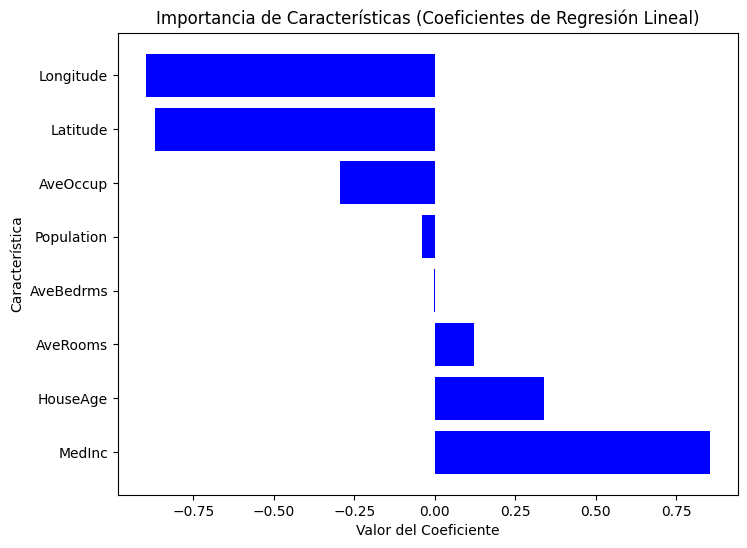

In [ ]:
# Ordenar el dataframe por coeficientes.
coef_df_sorted = coef_df.sort_values(by="Coeficiente", ascending=False)


# Crear gráfico.
plt.figure(figsize=(8,6))
plt.barh(coef_df["Característica"], coef_df_sorted["Coeficiente"], color="blue")
plt.xlabel("Valor del Coeficiente")
plt.ylabel("Característica")
plt.title("Importancia de Características (Coeficientes de Regresión Lineal)")
plt.show()

Ahora, visualicemos los residuos y el ajuste de la regresión.

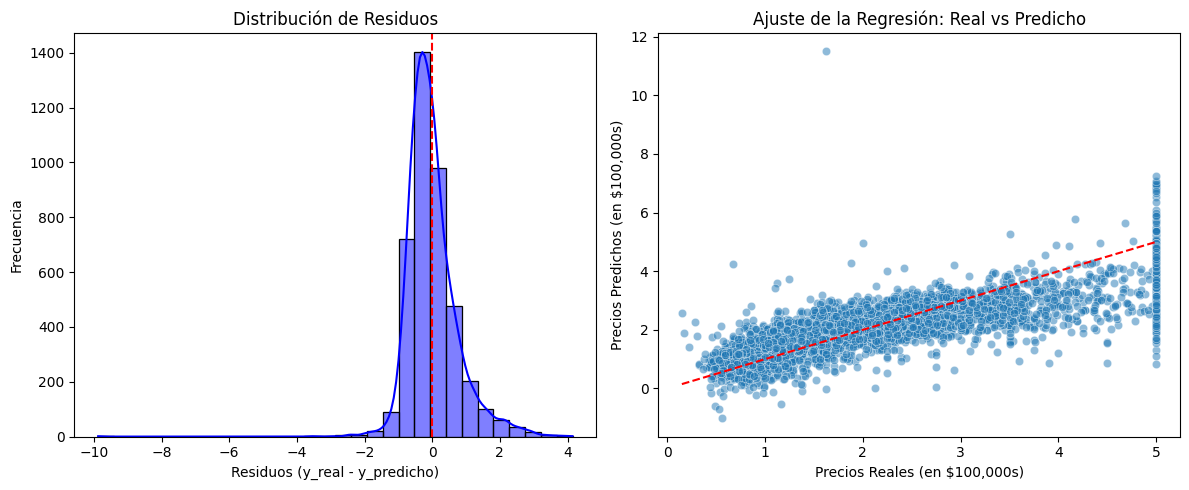

In [ ]:
# Calcular residuos.
residuals = y_test - y_pred


# Crear gráficos.
plt.figure(figsize=(12,5))


# Gráfico 1: Distribución de Residuos.
plt.subplot(1,2,1)
sns.histplot(residuals, bins=30, kde=True, color="blue")
plt.axvline(x=0, color='red', linestyle='--')
plt.title("Distribución de Residuos")
plt.xlabel("Residuos (y_real - y_predicho)")
plt.ylabel("Frecuencia")


# Gráfico 2: Ajuste de la Regresión (Real vs Predicho).
plt.subplot(1,2,2)
sns.scatterplot(x=y_test, y=y_pred, alpha=0.5)
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], color='red', linestyle='--')  # Línea de ajuste perfecto
plt.title("Ajuste de la Regresión: Real vs Predicho")
plt.xlabel("Precios Reales (en $100,000s)")
plt.ylabel("Precios Predichos (en $100,000s)")


# Mostrar gráficos.
plt.tight_layout()
plt.show()

La distribución de residuos (gráfico izquierdo) debe estar centrada alrededor de cero, lo que indica que los errores están distribuidos aleatoriamente. Si los residuos siguen una distribución normal, el modelo tiene buen ajuste, pero si hay asimetría o una tendencia, puede sugerir errores sistemáticos. El ajuste de la regresión (gráfico derecho) compara los valores reales vs. predichos, con la línea roja discontinua representando un ajuste perfecto. Si los puntos siguen de cerca la línea, las predicciones son precisas, pero si aparece un patrón (por ejemplo, una curva), la relación puede no ser verdaderamente lineal.

Estas visualizaciones ayudan a diagnosticar el sobreajuste o subajuste, revelan patrones en los residuos que sugieren relaciones faltantes y proporcionan una evaluación clara de la efectividad del modelo.

## Aplicaciones en el Mundo Real

La regresión lineal se usa ampliamente en diferentes industrias para la predicción y la toma de decisiones. En bienes raíces, estima precios de viviendas en función de factores como el tamaño y la ubicación.

Las ventas y el marketing la usan para la previsión de demanda y la optimización del presupuesto, mientras que la atención médica la aplica para la evaluación del riesgo de enfermedades. En finanzas, ayuda en la predicción de precios de acciones y la calificación crediticia, y en manufactura, ayuda con el control de calidad y la predicción de fallas.

### Cuándo usar la regresión lineal

- Las características y la variable objetivo tienen una relación lineal.
- La interpretabilidad y la simplicidad importan más que el modelado complejo.
- Los datos requieren una ingeniería de características mínima.

### Cuándo NO usar la regresión lineal

- La relación entre el objetivo y las características es compleja y no lineal.
- Los datos están altamente correlacionados.
- Los datos contienen valores atípicos que no se pueden eliminar. En este caso, puede ser necesario aplicar transformaciones de datos o usar estrategias para mitigar su impacto.

## Conclusión

La regresión lineal sigue siendo una de las técnicas más fundamentales y ampliamente utilizadas en el aprendizaje automático y el modelado estadístico. A pesar de su simplicidad, es una herramienta poderosa para comprender las relaciones entre variables y hacer predicciones en diversas aplicaciones del mundo real.

Aquí están los puntos clave del tutorial:

- **Aplicaciones versátiles**. La regresión lineal proporciona información valiosa en múltiples industrias y dominios de problemas.
- **Interpretable**. A diferencia de los modelos complejos de caja negra, la regresión lineal ofrece interpretaciones claras basadas en coeficientes, lo que facilita su interpretación y explicación.
- **Selección de características**. Seleccionar correctamente las características y abordar la multicolinealidad garantiza que los modelos permanezcan precisos, estables y confiables.

---

## Preguntas Frecuentes sobre la Regresión Lineal con Sklearn

**¿Qué es la regresión lineal y cómo funciona?**
La regresión lineal es un método estadístico utilizado para modelar la relación entre una variable objetivo y uno o más predictores. Encuentra la línea de mejor ajuste minimizando la diferencia entre los valores reales y predichos usando el método de mínimos cuadrados.

**¿Cuáles son los supuestos de la regresión lineal?**
- Linealidad: La relación entre predictores y la variable objetivo es lineal.
- Independencia: Las observaciones son independientes entre sí.
- Homocedasticidad: La varianza de los residuos es constante en todos los valores.
- Normalidad de los residuos: Los residuos deben estar normalmente distribuidos.
- Sin multicolinealidad: Las variables independientes no deben estar altamente correlacionadas.

**¿Por qué debo escalar las características antes de ajustar un modelo de regresión lineal?**
El escalado de características garantiza que todas las características contribuyan igualmente al modelo. Dado que la regresión lineal es sensible a las magnitudes de las características, el escalado evita que las variables con valores numéricos grandes dominen sobre aquellas con valores más pequeños. Usa `StandardScaler()` para la estandarización.

**¿Qué es la multicolinealidad y cómo puedo detectarla?**
La multicolinealidad ocurre cuando dos o más variables independientes están altamente correlacionadas, lo que hace que la interpretación de los coeficientes sea poco confiable. Se puede detectar usando el Factor de Inflación de la Varianza (VIF).

**¿Cómo evalúo un modelo de regresión lineal?**
Las métricas de rendimiento clave incluyen:
- R² (Coeficiente de Determinación) → Mide qué tan bien el modelo explica la varianza en la variable objetivo.
- MSE (Error Cuadrático Medio) → Mide el error cuadrático promedio entre los valores reales y predichos.
- RMSE (Raíz del Error Cuadrático Medio) → Una versión más interpretable del MSE.